# 01 · Exploratory data analysis

**Goal of the project:** predict *whether* a telecom customer will churn and *when*, then
decide who to target with a retention offer.

This notebook profiles the IBM Telco Customer Churn data (7,043 customers, one row each)
and answers three questions that shape the modeling:

1. Is the raw data clean enough to model, and what has to be fixed?
2. Which customer attributes are associated with churn?
3. How does retention evolve over a customer's lifetime, and does it differ by contract?

**How to read the data.** It is a snapshot. `tenure` is months with the company, and
`Churn = Yes` means the customer left in the last month. For survival analysis, churners
therefore have an observed event at `tenure`, while active customers are *right-censored*:
we know they stayed at least `tenure` months, not when they will leave.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import pairwise_logrank_test

from churn import plots
from churn.config import CATEGORY_LEVELS
from churn.data import SCHEMA, clean_data, load_raw_data
from churn.survival import logrank_by_group, survival_frame

plots.apply_style()
pd.set_option("display.precision", 3)

## 1. Load, clean and validate

`TotalCharges` arrives as text. Coercing it to numbers exposes 11 blanks:

In [2]:
raw = load_raw_data()
blank = raw["TotalCharges"].str.strip() == ""
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns; {blank.sum()} blank TotalCharges")
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

7,043 rows x 21 columns; 11 blank TotalCharges


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Every blank belongs to a customer with `tenure = 0`, a brand-new customer who has not
been billed yet. The correct value is therefore **0**, not an imputed median (which would
invent roughly $1,400 of history for someone who joined this month).

`clean_data` applies that fix, encodes the target (`Churn`: 1 = churned), recodes
`SeniorCitizen` to Yes/No like every other flag, and validates the result against a
[pandera](https://pandera.readthedocs.io) schema. The schema checks types, allowed levels,
value ranges, unique IDs and cross-column consistency. For example, add-on services must
read "No internet service" exactly when `InternetService` is "No".

In [3]:
df = clean_data(raw)  # raises a SchemaErrors report if any check fails
print(
    f"Schema '{SCHEMA.name}': {len(SCHEMA.columns)} columns, {len(SCHEMA.checks)} table-level checks passed"
)
df.head()

Schema 'telco_clean': 21 columns, 2 table-level checks passed


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [4]:
summary = pd.DataFrame(
    {
        "customers": [len(df)],
        "churned": [int(df["Churn"].sum())],
        "churn rate": [f"{df['Churn'].mean():.1%}"],
        "median tenure (months)": [df["tenure"].median()],
        "median monthly charge": [f"${df['MonthlyCharges'].median():.2f}"],
    }
)
summary

,customers,churned,churn rate,median tenure (months),median monthly charge
0,7043,1869,26.5%,29.0,$70.35


26.5% of customers churned, so the classes are imbalanced but not extremely so. We
will report PR-AUC next to ROC-AUC, and we will **not** re-weight classes: re-weighting
distorts predicted probabilities, and the business layer needs them to be honest.

## 2. Who churns? Rates by contract, tenure and payment method

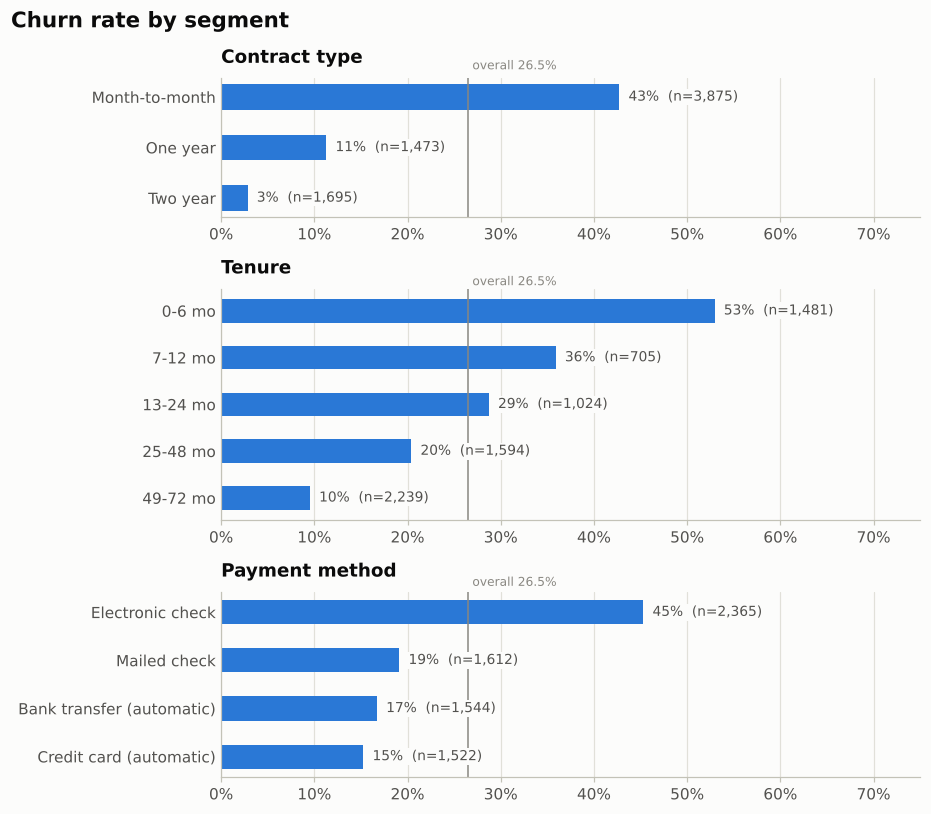

In [5]:
df["tenure band"] = pd.cut(
    df["tenure"],
    [-1, 6, 12, 24, 48, 72],
    labels=["0-6 mo", "7-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"],
)

fig, axes = plt.subplots(3, 1, figsize=(8.5, 7.5), gridspec_kw={"height_ratios": [3, 5, 4]})
plots.plot_churn_rate_by(df, "Contract", order=CATEGORY_LEVELS["Contract"][::-1], ax=axes[0])
plots.plot_churn_rate_by(
    df, "tenure band", order=df["tenure band"].cat.categories[::-1], ax=axes[1]
)
plots.plot_churn_rate_by(df, "PaymentMethod", ax=axes[2])
for ax, title in zip(axes, ["Contract type", "Tenure", "Payment method"], strict=True):
    ax.set_title(title)
    ax.set_ylabel("")
fig.suptitle("Churn rate by segment", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
plots.save_figure(fig, "churn_rate_by_segment")
plt.show()

The same numbers as a table, plus a few other attributes worth knowing about:

In [6]:
segments = [
    "Contract",
    "tenure band",
    "PaymentMethod",
    "InternetService",
    "PaperlessBilling",
    "SeniorCitizen",
    "TechSupport",
]
rates = pd.concat(
    {
        col: df.groupby(col, observed=True)["Churn"].agg(churn_rate="mean", customers="size")
        for col in segments
    },
    names=["attribute", "level"],
)
rates.assign(churn_rate=rates["churn_rate"].map("{:.1%}".format))

churn_rate  customers
attribute        level                                          
Contract         Month-to-month                 42.7%       3875
                 One year                       11.3%       1473
                 Two year                        2.8%       1695
tenure band      0-6 mo                         52.9%       1481
                 7-12 mo                        35.9%        705
                 13-24 mo                       28.7%       1024
                 25-48 mo                       20.4%       1594
                 49-72 mo                        9.5%       2239
PaymentMethod    Bank transfer (automatic)      16.7%       1544
                 Credit card (automatic)        15.2%       1522
                 Electronic check               45.3%       2365
                 Mailed check                   19.1%       1612
InternetService  DSL                            19.0%       2421
                 Fiber optic                    41.9%       3096
                 No                              7.4%       1526
PaperlessBilling No                             16.3%       2872
                 Yes                            33.6%       4171
SeniorCitizen    No                             23.6%       5901
                 Yes                            41.7%       1142
TechSupport      No                             41.6%       3473
                 No internet service             7.4%       1526
                 Yes                            15.2%       2044

**Observations**

* **Contract is the dominant signal.** Month-to-month customers churn at 43%, against 11%
  for one-year and 3% for two-year contracts. Contracts mechanically lock customers in, so
  this is partly a *consequence* of commitment rather than a cause we could act on directly.
* **Churn concentrates early.** 53% of customers in their first six months churned,
  falling steadily to under 10% beyond four years.
* **Electronic-check payers churn at 45%**, about three times the rate of automatic
  payers (15-17%). Fiber-optic customers (42%), seniors (42%) and customers without tech
  support (42%) also stand out.
* Many of these attributes are correlated (month-to-month customers are also newer and
  more likely to pay by electronic check), so the one-way rates above overstate each
  attribute's independent effect. The models in notebooks 02 and 03 separate them.

## 3. Tenure and monthly charges

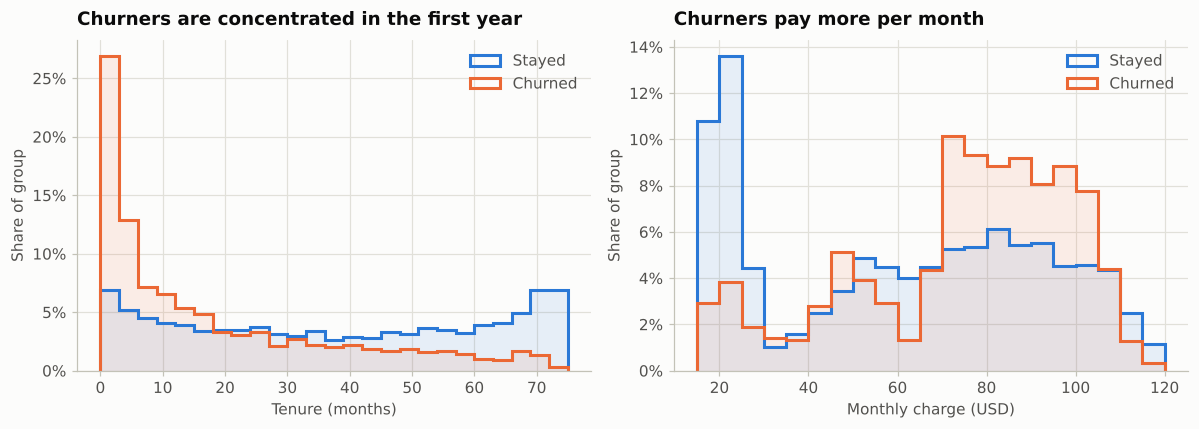

,tenure,MonthlyCharges
Churn,,
stayed,38.0,64.425
churned,10.0,79.650


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plots.plot_distribution_by_churn(df, "tenure", bins=np.arange(0, 76, 3), ax=axes[0])
axes[0].set_xlabel("Tenure (months)")
axes[0].set_title("Churners are concentrated in the first year")
plots.plot_distribution_by_churn(df, "MonthlyCharges", bins=np.arange(15, 125, 5), ax=axes[1])
axes[1].set_xlabel("Monthly charge (USD)")
axes[1].set_title("Churners pay more per month")
fig.tight_layout()
plots.save_figure(fig, "tenure_and_charges_distribution")
plt.show()

df.groupby("Churn")[["tenure", "MonthlyCharges"]].median().rename(index={0: "stayed", 1: "churned"})

The median churner left after **10 months** and was paying **$80/month**. The median active
customer has been around for 38 months and pays $64. The spike of retained customers at
70+ months is the long-tenure, mostly two-year-contract base.

The tenure histogram for active customers is **not** a lifetime distribution: those
customers are still active, so their tenure is a lower bound on how long they will stay.
Treating it as a lifetime would bias every "time to churn" estimate downwards. That is why
the next section uses survival analysis.

## 4. Retention curves: Kaplan-Meier by contract type

The Kaplan-Meier estimator uses censored customers correctly: each contributes to the
at-risk population until their current tenure. The 11 customers with `tenure = 0` carry no
follow-up time and are dropped from the survival analysis.

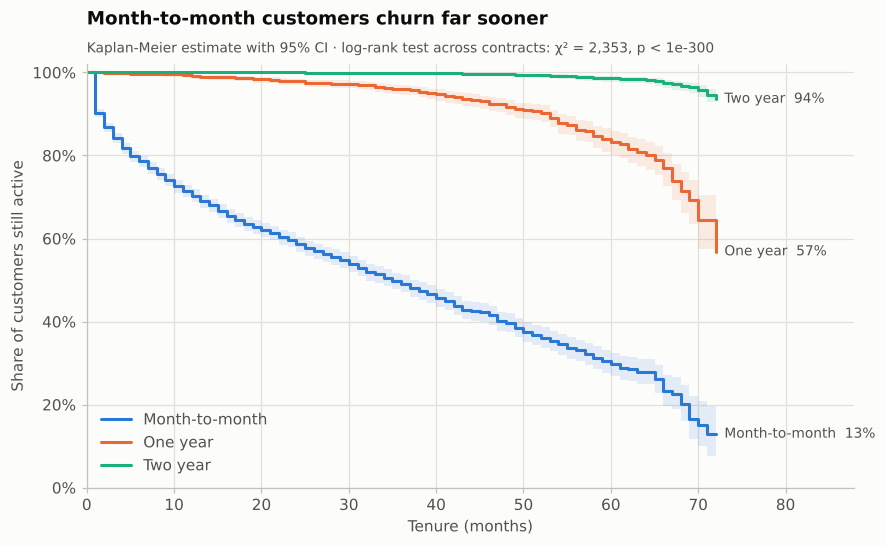

In [8]:
surv_df = survival_frame(df)
contract_order = CATEGORY_LEVELS["Contract"]

fig, ax = plt.subplots(figsize=(9, 5))
plots.plot_km_by_group(surv_df, "Contract", contract_order, ax=ax)
logrank = logrank_by_group(surv_df, "Contract")
plots.set_title(
    ax,
    "Month-to-month customers churn far sooner",
    "Kaplan-Meier estimate with 95% CI · log-rank test across contracts: "
    f"χ² = {logrank.test_statistic:,.0f}, {plots.format_p(logrank.p_value)}",
)
plots.save_figure(fig, "km_by_contract")
plt.show()

In [9]:
pairwise = pairwise_logrank_test(surv_df["tenure"], surv_df["Contract"], surv_df["Churn"])
pairwise.summary[["test_statistic", "p"]]

test_statistic           p
Month-to-month One year         926.065  2.117e-203
               Two year        1550.510   0.000e+00
One year       Two year         256.218   1.145e-57

In [10]:
rows = {}
for level in contract_order:
    sub = surv_df[surv_df["Contract"] == level]
    km = KaplanMeierFitter().fit(sub["tenure"], sub["Churn"])
    at = km.survival_function_at_times([12, 24, 48, 72]).to_numpy()
    rows[level] = {
        "customers": len(sub),
        "retained at 12 mo": at[0],
        "retained at 24 mo": at[1],
        "retained at 48 mo": at[2],
        "retained at 72 mo": at[3],
        "median lifetime (mo)": km.median_survival_time_,
    }
retention = pd.DataFrame(rows).T


def fmt(col: pd.Series) -> pd.Series:
    if col.name.startswith("retained"):
        return col.map("{:.1%}".format)
    if col.name.startswith("median"):  # infinite when the curve never drops below 50%
        return col.map(lambda v: f"{v:.0f}" if np.isfinite(v) else "not reached")
    return col.map("{:,.0f}".format)


retention.apply(fmt)

,customers,retained at 12 mo,retained at 24 mo,retained at 48 mo,retained at 72 mo,median lifetime (mo)
Month-to-month,"3,875",70.3%,58.6%,39.7%,12.9%,35
One year,"1,472",99.1%,97.8%,91.7%,56.8%,not reached
Two year,"1,685",100.0%,100.0%,99.6%,93.6%,not reached


* The three contract groups have clearly different retention curves (log-rank p ≈ 0
  overall and for every pair).
* Month-to-month customers have a **median lifetime of 35 months**. Only 70% are still
  active after a year and 13% after six years. One- and two-year customers never reach
  50% churn within the observation window (median "not reached"), and 94% of two-year customers
  are still active at 72 months.
* The curves are **not proportional**. The month-to-month curve drops steeply in the
  first year and then flattens, while the one-year curve stays flat for 12 months
  (the contract term) before declining. A Cox model that assumes a constant hazard ratio
  for contract type is therefore suspect. Notebook 03 tests this formally and stratifies
  on contract.

## 5. Takeaways for modeling

| Finding | Modeling decision |
|---|---|
| Blank `TotalCharges` = unbilled new customers | Fill with 0, enforced by a schema check |
| 26.5% churn rate, probabilities feed a profit calculation | No class re-weighting; check calibration; report PR-AUC |
| Strong, correlated categorical drivers | Multivariate models; one-hot encoding with "No internet service" collapsed to "No" to avoid duplicate columns |
| Churn is front-loaded and censored | Survival models with `tenure` as time and `Churn` as event |
| `TotalCharges` ≈ `tenure` × `MonthlyCharges` | Exclude tenure-derived features from survival covariates (they leak the outcome) |
| Contract curves cross / converge | Test proportional hazards; stratify Cox by contract |